                                        Singapore  Hong Kong
Price growth 2017Q1-2025Q4 (%)               52.1       -5.5
Median income growth (%)                     37.9       14.1
Final affordability index (2017Q1=100)      110.3       82.9

=== Singapore ===
 fold  Naive  OLS  Ridge (scaled)  Random Forest
    1   8.67 3.30            2.07           1.26
    2   2.68 2.78            2.05           2.51
    3   2.96 4.97            4.84           5.40
    4   2.72 3.56            3.33           2.94

=== Hong Kong ===
 fold  Naive  OLS  Ridge (scaled)  Random Forest
    1  11.40 7.59            6.48           8.87
    2  11.03 6.18            5.02          14.26
    3  12.00 4.23            4.31           6.22
    4   4.11 3.40            3.34           1.83

Mean test RMSE (pp):
           Naive   OLS  Ridge (scaled)  Random Forest
Singapore   4.26  3.65            3.07           3.03
Hong Kong   9.64  5.35            4.79           7.80


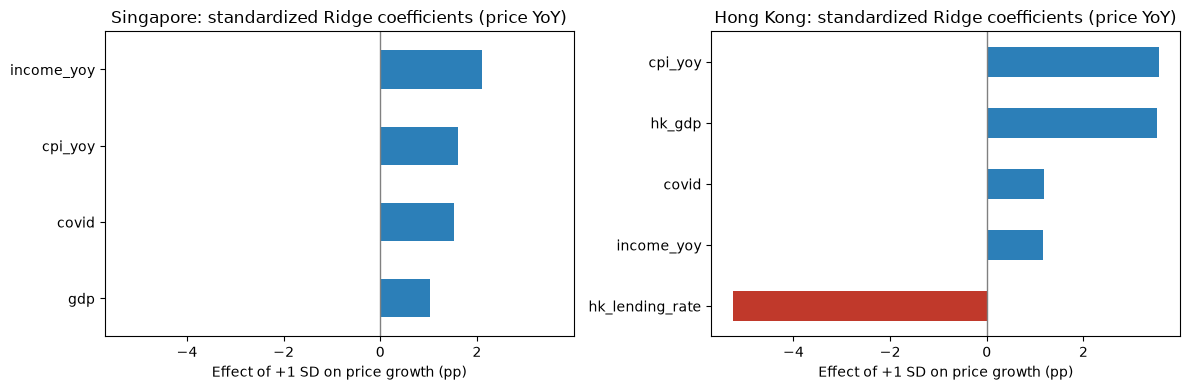

In [1]:
from prep import *
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---------- 1. Affordability summary (descriptive half of the research question) ----------
afford = pd.DataFrame({
    'Singapore': [sg['price_idx'].iloc[-1] - 100, sg['income_idx'].iloc[-1] - 100, sg['afford_idx'].iloc[-1]],
    'Hong Kong': [hk['price_idx'].iloc[-1] - 100, hk['income_idx'].iloc[-1] - 100, hk['afford_idx'].iloc[-1]],
}, index=['Price growth 2017Q1-2025Q4 (%)', 'Median income growth (%)', 'Final affordability index (2017Q1=100)']).round(1)
print(afford)
afford.to_csv('Data/Clean/affordability_summary.csv')

# ---------- 2. Model comparison (4-fold expanding-window CV, min train = 16) ----------
def make_models():
    return {
        'OLS': LinearRegression(),
        'Ridge (scaled)': make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))),
        'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42),
    }

def run_cv(df, target, feats):
    d = df.dropna(subset=[target] + feats)
    X, y = d[feats].values, d[target].values
    rows = []
    for k, (tr, te) in enumerate(TimeSeriesSplit(n_splits=4, test_size=4).split(X), 1):
        rmse = lambda p: np.sqrt(mean_squared_error(y[te], p))
        r = {'fold': k, 'Naive': rmse(np.full(len(te), y[tr].mean()))}
        for name, m in make_models().items():
            m.fit(X[tr], y[tr]); r[name] = rmse(m.predict(X[te]))
        rows.append(r)
    folds = pd.DataFrame(rows).round(2)
    final = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))).fit(X, y)
    coef = pd.Series(final[-1].coef_, index=feats)
    return folds, coef

sg_folds, sg_coef = run_cv(sg, 'price_yoy', sg_feats_yoy)
hk_folds, hk_coef = run_cv(hk, 'price_yoy', hk_feats_yoy)

for name, f in [('Singapore', sg_folds), ('Hong Kong', hk_folds)]:
    print(f'\n=== {name} ===')
    print(f.to_string(index=False))

cols = ['Naive', 'OLS', 'Ridge (scaled)', 'Random Forest']
results = pd.DataFrame({'Singapore': sg_folds[cols].mean(), 'Hong Kong': hk_folds[cols].mean()}).T.round(2)
print('\nMean test RMSE (pp):'); print(results)

sg_folds.assign(city='Singapore').pipe(lambda a: pd.concat([a, hk_folds.assign(city='Hong Kong')])) \
        .to_csv('Data/Clean/cv_folds.csv', index=False)
results.to_csv('Data/Clean/model_comparison_results.csv')
pd.DataFrame({'Singapore': sg_coef, 'Hong Kong': hk_coef}).round(2).to_csv('Data/Clean/ridge_coefficients.csv')

# ---------- 3. Coefficient chart (shared x-axis) ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, c, t in [(axes[0], sg_coef, 'Singapore'), (axes[1], hk_coef, 'Hong Kong')]:
    c = c.sort_values()
    c.plot.barh(ax=ax, color=['#c0392b' if v < 0 else '#2c7fb8' for v in c])
    ax.axvline(0, color='gray', linewidth=1)
    ax.set_title(f'{t}: standardized Ridge coefficients (price YoY)')
    ax.set_xlabel('Effect of +1 SD on price growth (pp)')
plt.tight_layout()
plt.savefig('Figures/ridge_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()